For this project I use the Bank Marketing dataset(bank-additional-full) from the UCI Machine Learning Repository. It contains data from direct marketing campaigns (phone calls) of a Portuguese bank. The classification goal is to predict if the client will subscribe a term deposit (variable y). 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_curve,
                             precision_recall_curve, ConfusionMatrixDisplay,
                             classification_report)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('bank-additional-full.csv', sep=';')

**Task:** Perform FULL and comprehensive EDA (check imbalance, visualize key features vs
target, correlation heatmap). Describe the dataset (rows, features, target). Show
class distribution (plot required)

In [3]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
df.shape

(41188, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [6]:
print(df.describe())

               age      duration      campaign         pdays      previous  \
count  41188.00000  41188.000000  41188.000000  41188.000000  41188.000000   
mean      40.02406    258.285010      2.567593    962.475454      0.172963   
std       10.42125    259.279249      2.770014    186.910907      0.494901   
min       17.00000      0.000000      1.000000      0.000000      0.000000   
25%       32.00000    102.000000      1.000000    999.000000      0.000000   
50%       38.00000    180.000000      2.000000    999.000000      0.000000   
75%       47.00000    319.000000      3.000000    999.000000      0.000000   
max       98.00000   4918.000000     56.000000    999.000000      7.000000   

       emp.var.rate  cons.price.idx  cons.conf.idx     euribor3m   nr.employed  
count  41188.000000    41188.000000   41188.000000  41188.000000  41188.000000  
mean       0.081886       93.575664     -40.502600      3.621291   5167.035911  
std        1.570960        0.578840       4.628198    

Numeric vs Categorical features

In [7]:
X = df.drop(columns='y')   

numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude='number').columns.tolist()

print('Numeric:', numeric_features, len(numeric_features))
print('\nCategorical:', categorical_features, len(categorical_features))

Numeric: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'] 10

Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome'] 10


Duplicates:

In [8]:
print("duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

duplicates: 12


12 fully duplicated rows (0.03% of the data) were found and removed them. Duplicates add no new information, give extra weight to repeated observations, and could end up in both the train and test sets, which would lead to data leakage and overly optimistic test metrics. After removal the dataset contains 41,176 rows.

Hidden passes

In [9]:
print((df == "unknown").sum())

age                  0
job                330
marital             80
education         1730
default           8596
housing            990
loan               990
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dtype: int64


The dataset has no explicit NaN values, but several categorical features use the label "unknown" for missing information: job (330), marital (80), education (1,730), default (8,596), housing (990) and loan (990). I do not drop these rows, because that would remove a large share of the data (default alone is ~21% unknown), including valuable minority-class (“yes”) examples. Missingness may also be informative.

Class distribution + imbalance

y
no     36537
yes     4639
Name: count, dtype: int64
y
no     0.887
yes    0.113
Name: proportion, dtype: float64
Imbalance ratio (no:yes) = 7.9 : 1


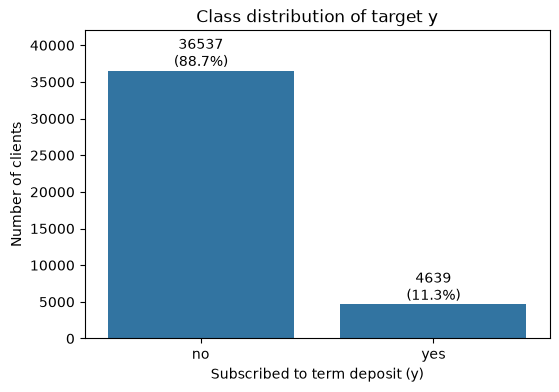

In [10]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True).round(3))
print("Imbalance ratio (no:yes) = %.1f : 1" % (df["y"].eq("no").sum() / df["y"].eq("yes").sum()))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x="y", data=df)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f}\n({p.get_height()/len(df):.1%})",
                (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax.set(title="Class distribution of target y", xlabel="Subscribed to term deposit (y)",
       ylabel="Number of clients")
ax.set_ylim(0, df["y"].eq("no").sum() * 1.15)
plt.show()

The target is highly imbalanced: 36,537 clients (88.7%) did not subscribe and only 4,639 (11.3%) did, a ratio of about 7.9 : 1. This reflects the nature of direct telemarketing: most cold calls end in a refusal, because a term deposit locks money for a fixed period. The data was also collected during the 2008-2010 financial crisis, when clients were more cautious. Since this is the real distribution, I keep it in the data but account for it in modelling. Accuracy is misleading here: a model that always predicts “no” would reach 88.7% accuracy and still find zero subscribers.

Key features vs target

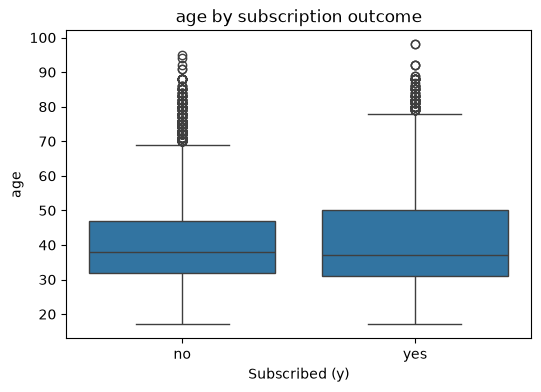

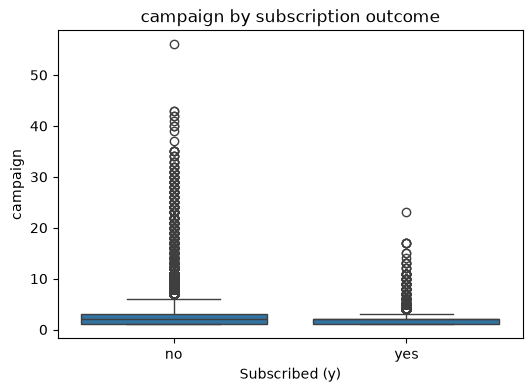

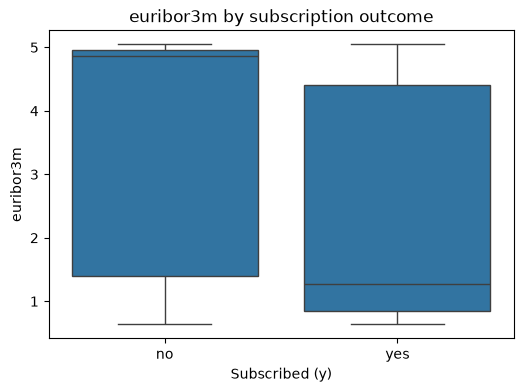

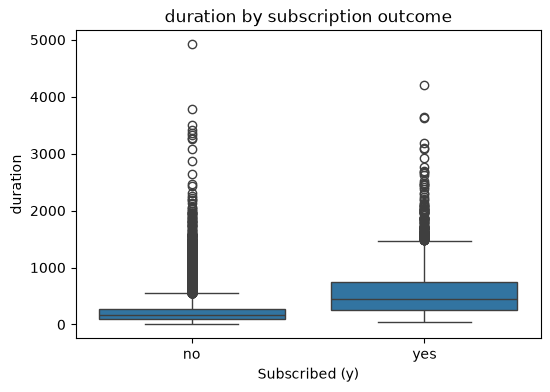

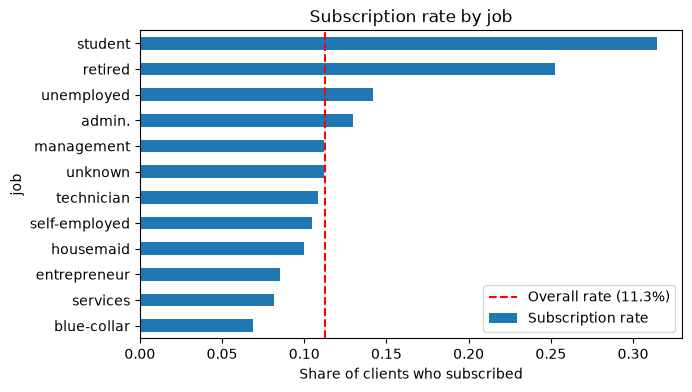

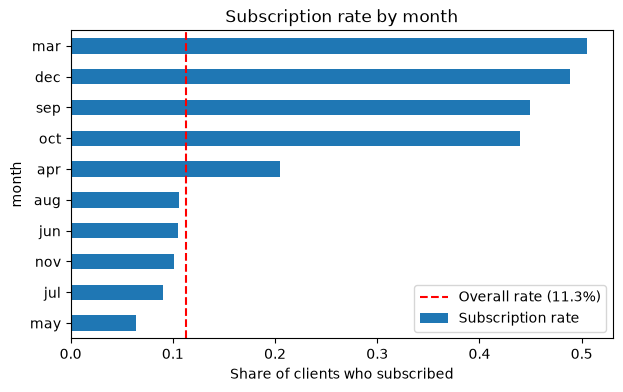

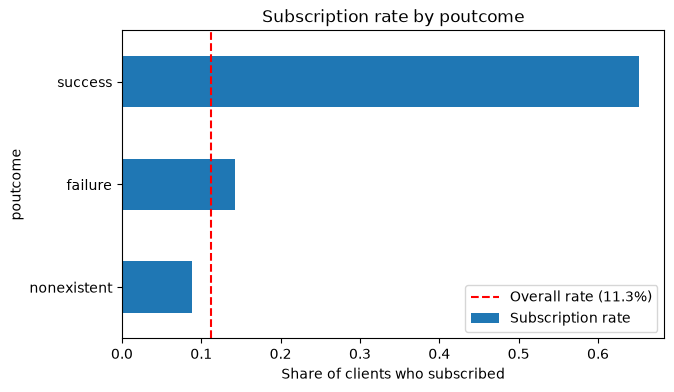

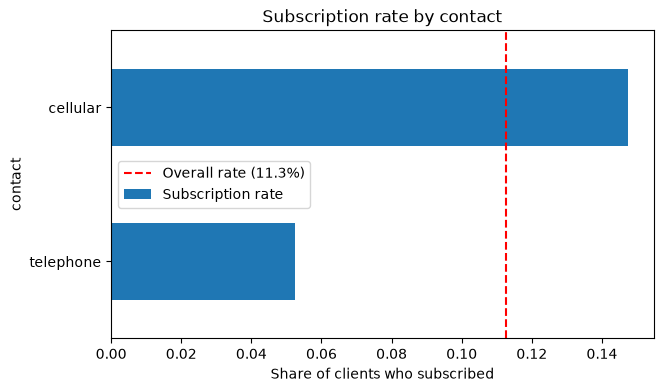

In [11]:
for col in ["age", "campaign", "euribor3m", "duration"]:
    plt.figure(figsize=(6, 4))
    ax = sns.boxplot(x="y", y=col, data=df)
    ax.set(title=f"{col} by subscription outcome", xlabel="Subscribed (y)", ylabel=col)
    plt.show()

overall = df["y"].eq("yes").mean()
for col in ["job", "month", "poutcome", "contact"]:
    rate = df.groupby(col)["y"].apply(lambda s: (s == "yes").mean()).sort_values()
    plt.figure(figsize=(7, 4))
    ax = rate.plot(kind="barh", label="Subscription rate")
    ax.axvline(overall, color="red", ls="--", label=f"Overall rate ({overall:.1%})")
    ax.set(title=f"Subscription rate by {col}", xlabel="Share of clients who subscribed",
           ylabel=col)
    ax.legend()
    plt.show()

- Age vs y. The median age is almost the same for both classes (~38 vs ~37), so age alone is a weak predictor. However, the “yes” group has a wider spread and a higher upper whisker (up to ~78 vs ~69), which means older clients (60+) subscribe relatively more often. The relationship is non-linear, so tree-based models should capture it better than a linear model.
- Campaign vs y. campaign is the number of contacts with the client during the current campaign. Subscribers were usually reached in 1–3 calls, while the “no” group has many extreme values (up to 56 calls). Repeated calls rarely change the client’s decision: if a client does not agree after the first few contacts, more calls are unlikely to help.
- Euribor3m vs y. Euribor 3m is the 3-month Euro Interbank Offered Rate, a macroeconomic indicator that is the same for all clients contacted on the same day. The median rate is ~4.9% for “no” but only ~1.3% for “yes”: clients subscribed much more often when interest rates were low. Low rates correspond to the 2009–2010 crisis period, when people looked for safe savings options. This shows that economic conditions strongly influence campaign success.
- Duration vs y. duration is the length of the last call in seconds. Calls with subscribers are much longer (median ~450 s vs ~160 s). However, this is data leakage: duration is known only after the call ends, when the outcome is already decided, so it cannot be used to decide whom to call. Following the dataset documentation, I drop duration before modelling.
- Subscription rate by job. Students (~31%) and retired clients (~25%) subscribe far above the overall rate of 11.3%. Students are young and have few financial obligations, while retired clients usually have savings, prefer low-risk products and have time to listen to the offer. Blue-collar workers, services and entrepreneurs have the lowest rates, possibly because they have less free money or invest it elsewhere (e.g. in their business).
- Subscription rate by month. March, December, September and October have the highest rates (~45–50%), while May has the lowest (~6%). This is mainly explained by call volume: May was a mass-calling month (about a third of all contacts) with untargeted calls, so conversion was low. In the best months the bank made very few, more targeted calls, mostly during the low-interest period. Month therefore partly reflects campaign strategy and economic conditions, not only seasonality.
- Subscription rate by poutcome. poutcome is the outcome of the previous marketing campaign for the client. Clients who subscribed before (success) agree again in ~65% of cases, almost 6 times the overall rate. Clients previously contacted without success (~14%) are still slightly above average, while new clients (nonexistent, ~9%) are below it. Past positive experience with the bank is the strongest individual signal of interest.
- Subscription rate by contact. cellular means the client was called on a mobile phone and telephone on a landline. Mobile calls convert almost 3 times better (~14.7% vs ~5.2%). A mobile phone reaches the client personally at a convenient time, while a landline call may be answered by another family member or missed. The bank should prioritise mobile contacts.

Correlation heatmap

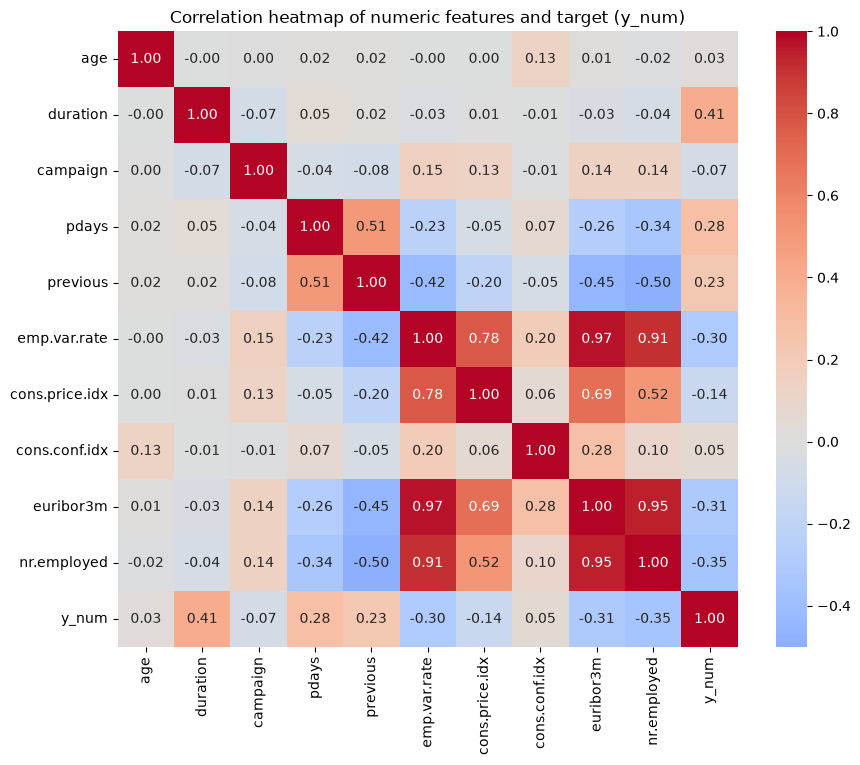

In [12]:
df["y_num"] = (df["y"] == "yes").astype(int)
corr_df = df.select_dtypes("number").copy()
corr_df["pdays"] = corr_df["pdays"].replace(999, -1)

plt.figure(figsize=(10, 8))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap of numeric features and target (y_num)")
plt.show()

Correlation heatmap. The strongest correlations are between the macroeconomic indicators: emp.var.rate-euribor3m (0.97), euribor3m-nr.employed (0.95) and emp.var.rate-nr.employed (0.91). These features describe the state of the Portuguese economy at the time of the call rather than the client, and they all follow the same economic cycle: during the 2008–2010 crisis employment fell and the European Central Bank lowered interest rates. The consumer price index is also related to them (0.78 with emp.var.rate, 0.69 with euribor3m), but more weakly. previous is moderately negatively correlated with nr.employed (-0.50), because repeated contacts happened mostly in the later, crisis period.

Correlation with the target. duration has the highest correlation (0.41), but it is excluded due to data leakage. Among the usable features, the macroeconomic indicators are the most informative and correlate negatively with subscription (nr.employed −0.35, euribor3m −0.31, emp.var.rate −0.30): clients subscribed more often when interest rates and employment were low. pdays (0.28) and previous (0.23) correlate positively, which confirms that previously contacted clients are more likely to subscribe. age, campaign and cons.conf.idx show almost no linear relationship with the target. Pearson correlation only captures linear effects; for example, the age boxplot and the job chart show a non-linear effect of age.

Key Findings



- Dataset. 41,188 rows (41,176 after removing 12 duplicates), 20 features (10 numeric, 10 categorical) and a binary target y (subscribed to a term deposit: yes/no).
- Strong class imbalance. Only 11.3% of clients subscribed (ratio ≈ 7.9 : 1), so accuracy is not a suitable metric. PR-AUC, F1, Precision and Recall will be used, and the imbalance must be handled during training.
- Hidden missing values. No explicit NaNs, but 6 categorical features contain "unknown" (up to ~21% in default). In addition, pdays = 999 is a placeholder meaning “not previously contacted”.
- Data leakage. duration has the highest correlation with the target (0.41), but it is known only after the call ends, so it must be excluded.
- Economic context matters most. Macroeconomic indicators (nr.employed, euribor3m, emp.var.rate) are the most informative usable features: subscriptions were much more frequent when interest rates and employment were low (2009–2010 crisis period).
- Client history is a strong signal. Clients with a successful previous campaign (poutcome = success) subscribe in ~65% of cases, and previously contacted clients in general are more likely to subscribe.
- Campaign strategy. Mobile contacts convert ~3× better than landlines; targeted months (Mar, Sep, Oct, Dec) perform far better than the mass-calling month of May; and more than 2–3 calls to the same client rarely help.
- Client profile. Students and retired clients are the most likely subscribers, blue-collar workers the least. Age has a weak, non-linear effect.
- Multicollinearity. emp.var.rate, euribor3m and nr.employed are almost duplicates (|r| = 0.91–0.97), so redundant ones should be removed for linear models.

Implications for preprocessing: remove duplicates, treat "unknown" and pdays = 999 as missing information, drop duration, handle skewed and outlier-heavy features (campaign, previous), encode categorical features, remove highly correlated features, scale numeric features and address class imbalance.

**Task:** Preprocess data (try to capture all tools from lecture material)

1. Missing values

In [13]:
df = df.replace("unknown", np.nan)
df.isnull().sum()

age                  0
job                330
marital             80
education         1730
default           8596
housing            990
loan               990
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
y_num                0
dtype: int64

I replace "unknown" with NaN so that pandas treats these values as real missing data. As long as "unknown" is a plain string, it is counted as a normal category: isnull() does not detect it, it could become the most frequent value during mode imputation, and one-hot encoding would create meaningless columns such as job_unknown. After the replacement, the missing values can be counted correctly and imputed with standard tools (fillna, mode).

In [14]:
pct = (df.isna().mean() * 100).round(2)
print(pct[pct > 0])
print("housing and loan are missing in the same rows:",
      (df["housing"].isna() == df["loan"].isna()).all())

#keep as separate category (constant fill, no leakage)
df["default"] = df["default"].fillna("unknown")

#Columns imputed with the TRAIN mode after the split (to avoid data leakage)
mode_cols = ["job", "marital", "education", "housing", "loan"]

job           0.80
marital       0.19
education     4.20
default      20.88
housing       2.40
loan          2.40
dtype: float64
housing and loan are missing in the same rows: True


After replacing "unknown" with NaN, the missing shares are: job 0.80%, marital 0.19%, education 4.20%, housing 2.40%, loan 2.40% and default 20.88%. Housing and loan are missing in exactly the same rows, which suggests that no loan information was recorded for these clients.

These features are categorical, so mean or median imputation is not applicable; I use the mode (most frequent value). For job, marital, education, housing and loan the missing share is small (< 5%), so mode imputation barely changes their distributions. To avoid data leakage, the mode is computed on the training set only after the train/test split and then applied to both sets.

default has ~21% missing values, and almost all known values are “no”, so mode imputation would heavily bias it. Instead, I keep "unknown" as a separate category (constant filling, which uses no data statistics and therefore causes no leakage), since the absence of credit information may itself be predictive.

2. Incorrect / inconsistent data

Numerical data

In [15]:
df.describe().T[["min", "max", "mean"]]

,min,max,mean
age,17.000,98.000,40.023800
duration,0.000,4918.000,258.315815
campaign,1.000,56.000,2.567879
pdays,0.000,999.000,962.464810
previous,0.000,7.000,0.173013
emp.var.rate,-3.400,1.400,0.081922
cons.price.idx,92.201,94.767,93.575720
cons.conf.idx,-50.800,-26.900,-40.502863
euribor3m,0.634,5.045,3.621293
nr.employed,4963.600,5228.100,5167.034870


In [16]:
rules = {
    "age":            lambda s: s.between(17, 100),
    "duration":       lambda s: s >= 0,
    "campaign":       lambda s: s >= 1,        # в текущей кампании звонили хотя бы раз
    "pdays":          lambda s: (s >= 0) & ((s <= 60) | (s == 999)),
    "previous":       lambda s: s >= 0,
    "euribor3m":      lambda s: s.between(-1, 10),
    "cons.price.idx": lambda s: s > 0,
    "nr.employed":    lambda s: s > 0,
}
for col, rule in rules.items():
    bad = (~rule(df[col])).sum()
    print(f"{col:15} invalid: {bad}")

age             invalid: 0
duration        invalid: 0
campaign        invalid: 0
pdays           invalid: 0
previous        invalid: 0
euribor3m       invalid: 0
cons.price.idx  invalid: 0
nr.employed     invalid: 0


Categorical Data

In [17]:
for col in df.select_dtypes(include=["object", "str"]).columns:
    print(col, sorted(df[col].dropna().unique()))

job ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed']
marital ['divorced', 'married', 'single']
education ['basic.4y', 'basic.6y', 'basic.9y', 'high.school', 'illiterate', 'professional.course', 'university.degree']
default ['no', 'unknown', 'yes']
housing ['no', 'yes']
loan ['no', 'yes']
contact ['cellular', 'telephone']
month ['apr', 'aug', 'dec', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
day_of_week ['fri', 'mon', 'thu', 'tue', 'wed']
poutcome ['failure', 'nonexistent', 'success']
y ['no', 'yes']


Links between columns

In [18]:
checks = {
    "previous=0, but poutcome != nonexistent":
        (df["previous"] == 0) & (df["poutcome"] != "nonexistent"),
    "previous>0, but poutcome == nonexistent":
        (df["previous"] > 0) & (df["poutcome"] == "nonexistent"),
    "pdays=999, but previous>0":
        (df["pdays"] == 999) & (df["previous"] > 0),
    "pdays!=999, but previous=0":
        (df["pdays"] != 999) & (df["previous"] == 0),
    "duration=0, but y=yes":
        (df["duration"] == 0) & (df["y"] == "yes"),
}
for name, mask in checks.items():
    print(f"{mask.sum():6}  {name}")

     0  previous=0, but poutcome != nonexistent
     0  previous>0, but poutcome == nonexistent
  4110  pdays=999, but previous>0
     0  pdays!=999, but previous=0
     0  duration=0, but y=yes


In [19]:

df["was_contacted_before"] = (df["previous"] > 0).astype(int)

df["pdays"] = df["pdays"].replace(999, np.nan)
df["pdays_known"] = df["pdays"].notna().astype(int)

I checked the data in three ways:

- Value ranges. All numeric features are within valid limits (0 invalid values): age is between 17 and 98, campaign ≥ 1, counts and durations are non-negative, and the macroeconomic indicators are in realistic ranges. The large mean of pdays (962) is caused by the placeholder value 999 (“not previously contacted”), not by an error.
- Categorical values. All categories are valid, with no typos, case or spacing variants (e.g. no “Married” vs “married”), so no category merging is needed.
- Cross-column consistency. previous and poutcome are fully consistent. However, 4,110 rows have pdays = 999 (“never contacted”) while previous > 0 and poutcome shows a real outcome of a previous campaign. Since two of the three columns agree that a prior contact happened, I treat pdays = 999 as an unrecorded value rather than “never contacted”.

Fix. I create was_contacted_before from previous (the reliable source) and replace 999 in pdays with NaN, adding a flag pdays_known that indicates whether the number of days since the last contact is recorded. Later, the remaining NaN in pdays is filled with −1 (“no information”). This also removes the artificial value 999, which would distort scaling and correlations.

3. Outliers

-Graphical

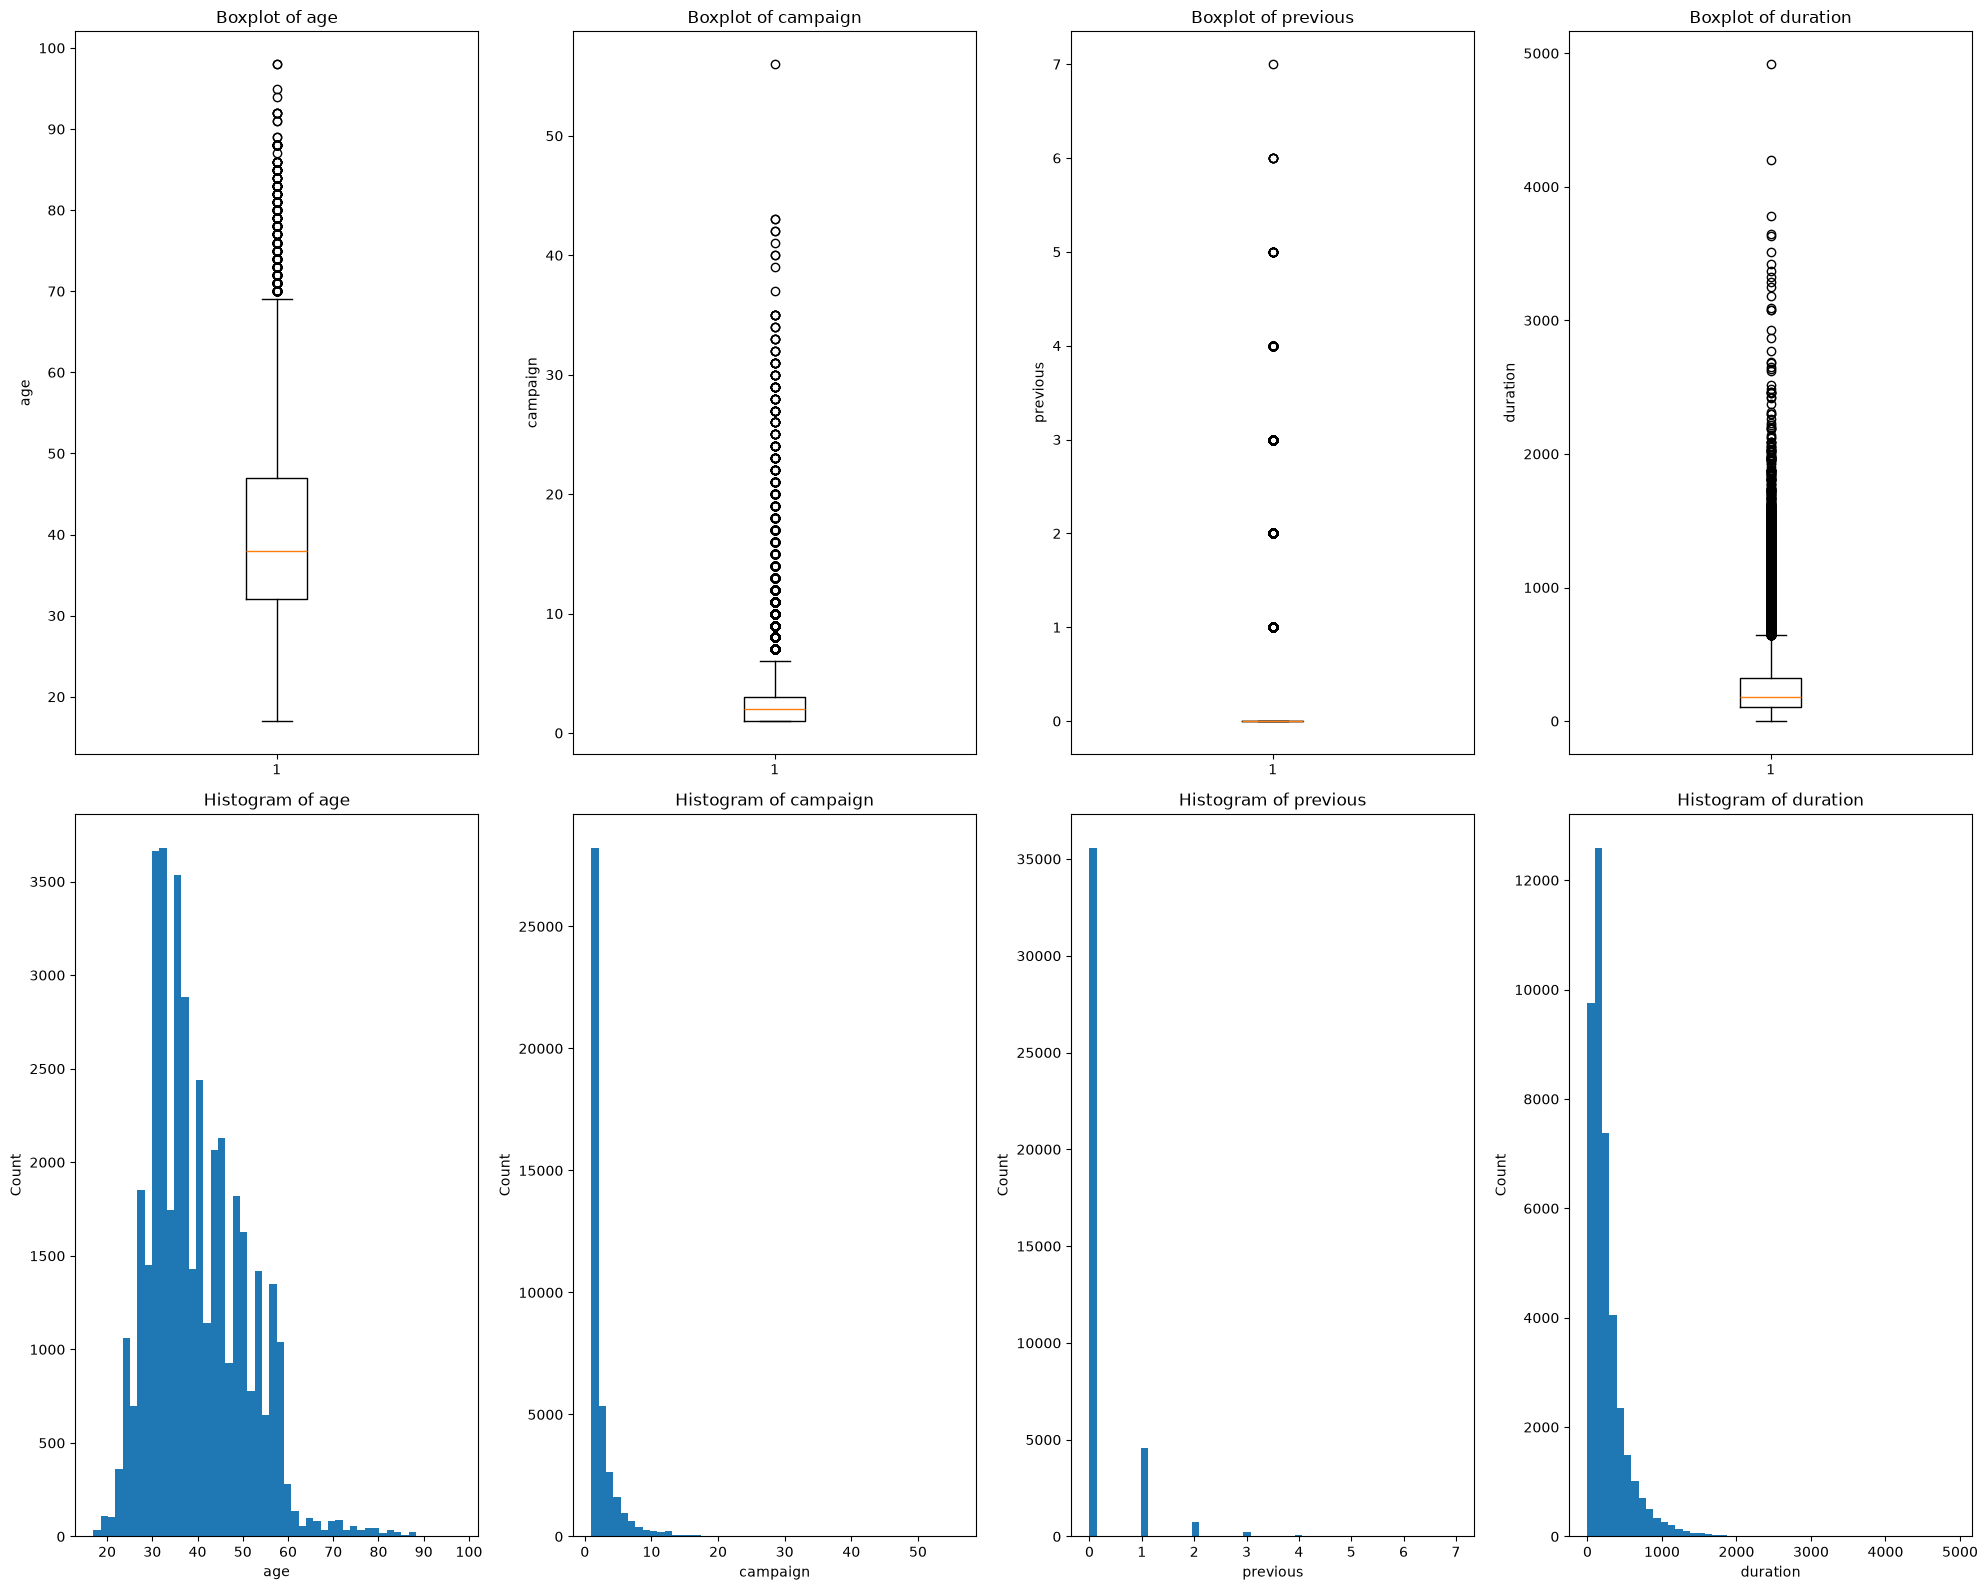

In [20]:
num_cols = ["age", "campaign", "previous", "duration"]

fig, axes = plt.subplots(2, len(num_cols), figsize=(20, 16))
for i, col in enumerate(num_cols):
    axes[0, i].boxplot(df[col])
    axes[0, i].set(title=f"Boxplot of {col}", ylabel=col)
    axes[1, i].hist(df[col], bins=50)
    axes[1, i].set(title=f"Histogram of {col}", xlabel=col, ylabel="Count")
plt.tight_layout()
plt.show()

Outliers - graphical method. Boxplots and histograms show that age is moderately right-skewed, with outliers above ~70 years. campaign, previous and duration are strongly right-skewed: most clients were contacted 1-3 times, had no previous contacts and had short calls, while a few values are extreme (up to 56 calls, 7 previous contacts and 4,918 seconds). These values are rare but realistic, not data-entry errors.

-Quartiles

In [21]:
def outliers_std(s, k=2):
    m, sd = s.mean(), s.std()
    return (s < m - k*sd) | (s > m + k*sd)

def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)

for col in num_cols:
    print(f"{col:10} std: {outliers_std(df[col]).sum():6}  "
          f"IQR: {outliers_iqr(df[col]).sum():6}")

age        std:    984  IQR:    468
campaign   std:   1377  IQR:   2406
previous   std:   1064  IQR:   5625
duration   std:   1902  IQR:   2963


Outliers - statistical methods. I compare two rules. The standard deviation rule (mean ± 2·std) assumes a normal distribution and is itself affected by extreme values. The IQR rule (outside Q1- 1.5·IQR, Q3 + 1.5·IQR) is based on quartiles and is robust to outliers. For skewed campaign and duration, IQR flags more points (2,406 and 2,963) because its upper bound is low (e.g. 6 calls for campaign). For previous, IQR flags 5,625 rows: 86% of values are 0, so Q1 = Q3 = 0 and IQR = 0, and every non-zero value is labelled an outlier. This shows that IQR is unreliable for discrete features dominated by one value. For age the std rule flags more points (984 vs 468).

-Distance-based

In [22]:
X_num = StandardScaler().fit_transform(df[num_cols])

nn = NearestNeighbors(n_neighbors=6).fit(X_num)   
dist, _ = nn.kneighbors(X_num)
knn_score = dist[:, -1]

thr = np.percentile(knn_score, 99)
knn_out = knn_score > thr
print("kNN outliers:", knn_out.sum())

kNN outliers: 412


Outliers — distance-based method (kNN). The first two methods check each feature separately. The kNN method scales the features and measures the distance from each row to its 5th nearest neighbour, so it also detects unusual combinations of values. Rows in the top 1% of distances (412 rows) are flagged as multivariate outliers.

4. Fixes

In [23]:
df["pdays"] = df["pdays"].fillna(-1)                 # -1 = no information (constant)
df = df.drop(columns=["duration", "y_num"])          # duration = leakage, y_num = helper

Final fixes before modelling. Most models (Logistic Regression, SVM, KNN) cannot handle NaN values, so the remaining NaN in pdays (the former placeholder 999) are filled with the constant −1, meaning “no information”. Real pdays values range from 0 to 27 days, so -1 is clearly distinguishable from them, and unlike 999 it does not create an artificial extreme value that would distort scaling. A constant fill uses no data statistics, so it causes no leakage, and the pdays_known flag keeps the information about whether the value was recorded.

I also drop two columns: duration, because it is known only after the call ends (data leakage), and y_num, a helper column created for the correlation heatmap. y_num is a numeric copy of the target, so keeping it as a feature would let the model see the answer directly.

5. Features/target

In [24]:
X = df.drop(columns="y")
y = (df["y"] == "yes").astype(int)
print("X:", X.shape)
print(y.value_counts())

X: (41176, 21)
y
0    36537
1     4639
Name: count, dtype: int64


The data is split into the feature matrix X and the target y. X contains 41,176 rows and 21 columns: the original input features (client attributes, contact and campaign information, previous campaign results and macroeconomic indicators) without duration, plus the two engineered flags was_contacted_before and pdays_known. The target y (whether the client subscribed to a term deposit) is converted from “yes”/”no” to 1/0, because models require numeric labels. Class 1 (“yes”) contains 4,639 clients and class 0 (“no”) 36,537, which confirms the 11.3% positive rate.

 6. Train

In [25]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Share of yes  train:", y_train.mean().round(3), "| test:", y_test.mean().round(3))

Train: (32940, 21) | Test: (8236, 21)
Share of yes  train: 0.113 | test: 0.113


The data is split into 80% train and 20% test. The model is trained only on the train set and evaluated on the unseen test set to estimate performance on new clients. stratify=y keeps the same share of “yes” (~11%) in both sets, which matters because the classes are imbalanced. random_state fixes the split for reproducibility.

In [26]:
X_train = X_train.copy()
X_test = X_test.copy()


for col in mode_cols:
    mode_val = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode_val)
    X_test[col] = X_test[col].fillna(mode_val)
    print(f"{col}: filled with '{mode_val}'")

q1, q3 = X_train["campaign"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
X_train["campaign"] = X_train["campaign"].clip(upper=upper)
X_test["campaign"] = X_test["campaign"].clip(upper=upper)
print("campaign capped at", upper)

print("Missing left:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

job: filled with 'admin.'
marital: filled with 'married'
education: filled with 'university.degree'
housing: filled with 'yes'
loan: filled with 'no'
campaign capped at 6.0
Missing left: 0 0


All statistics are computed on the training set only and then applied to both sets, so no information from the test set leaks into preprocessing. Missing categorical values are filled with the training mode: job -> “admin.”, marital -> “married”, education → “university.degree”, housing -> “yes”, loan -> “no”. campaign is capped at the IQR upper bound Q3 + 1.5·IQR = 3 + 1.5·2 = 6: all values above 6 (up to 56) are replaced by 6. This keeps the information that the client was called many times but removes extreme values that would dominate distance-based and linear models. After this step, no missing values remain in either set.

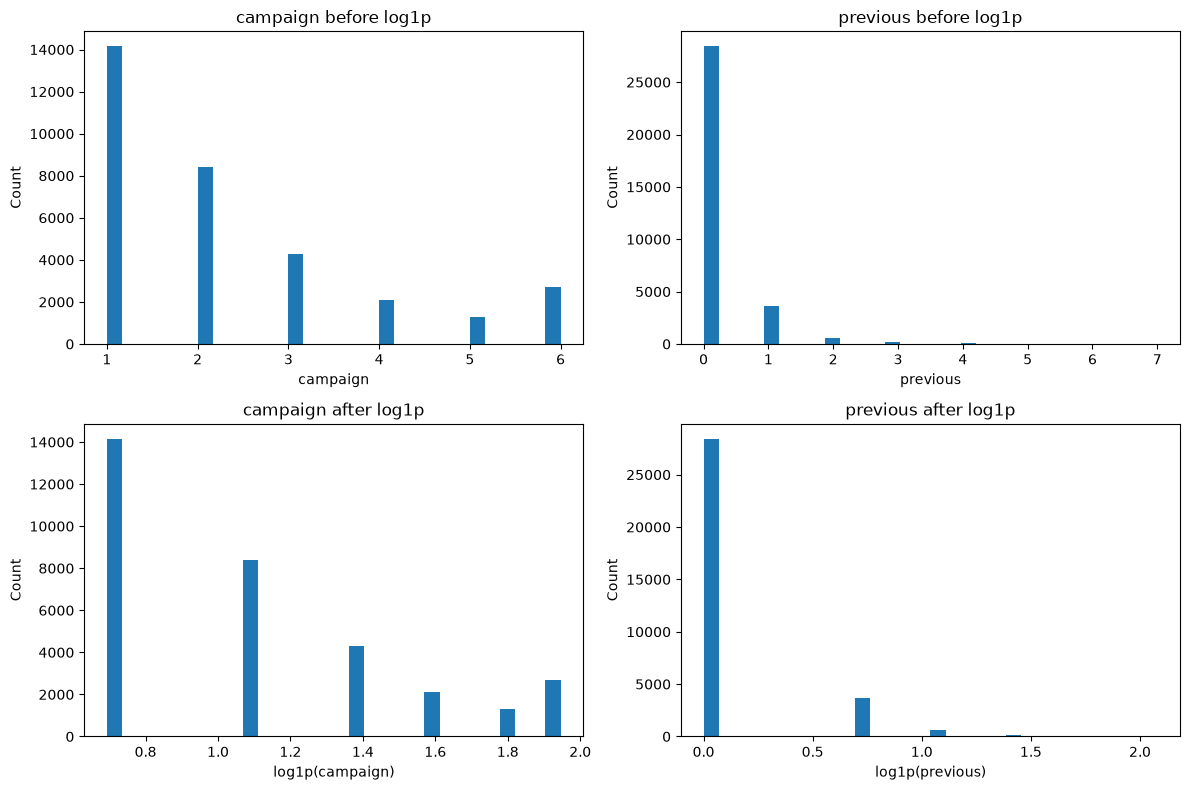

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, col in enumerate(["campaign", "previous"]):
    axes[0, i].hist(X_train[col], bins=30)
    axes[0, i].set(title=f"{col} before log1p", xlabel=col, ylabel="Count")
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])
    axes[1, i].hist(X_train[col], bins=30)
    axes[1, i].set(title=f"{col} after log1p", xlabel=f"log1p({col})", ylabel="Count")
plt.tight_layout()
plt.show()

campaign and previous are strongly right-skewed, so I apply log1p(x) = log(1 + x). log1p is used instead of log because previous contains zeros and log(0) is undefined. The histograms show that the effect on the shape is modest, because both features are discrete with only a few values. The main benefit is that large values are compressed: for campaign, the ratio between 6 and 1 calls drops from 6× to about 2.7× (1.95 vs 0.69), which reduces the influence of high values on distance-based and linear models (KNN, SVM, Logistic Regression). The transformation does not affect tree-based models, which only use the order of values. previous stays dominated by zeros (~86%), which a transformation cannot fix, so the binary flag was_contacted_before carries this information. The peak at 6 in campaign is caused by the capping step: it contains all clients who were called 6 or more times.

Feature Selection

In [28]:
num_feats = X_train.select_dtypes("number").columns
corr = X_train[num_feats].corr().abs()
upper_tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [c for c in upper_tri.columns if (upper_tri[c] > 0.9).any()]
print("Highly correlated (|r| > 0.9), dropped:", to_drop)

X_train = X_train.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)

Highly correlated (|r| > 0.9), dropped: ['euribor3m', 'nr.employed', 'was_contacted_before']


The correlation heatmap in the EDA showed that several macroeconomic indicators are almost duplicates. Here this is turned into an automatic rule: I compute the absolute correlation matrix on the training set only and, using its upper triangle (so each pair is checked once and the diagonal is ignored), drop every feature that has |r| > 0.9 with a previous feature. Three features are removed:

euribor3m and nr.employed, which are almost identical to emp.var.rate (r = 0.97 and 0.91); emp.var.rate is kept;
was_contacted_before, the engineered flag, which is highly correlated with previous (it equals 1 exactly when previous > 0, and most such clients have previous = 1).

Highly correlated features carry the same information. They make Logistic Regression coefficients unstable and give this information extra weight in distance-based models (KNN, SVM). Tree-based models are barely affected, so very little information is lost.

7. Encoding

In [29]:

edu_order = ["illiterate", "basic.4y", "basic.6y", "basic.9y",
             "high.school", "professional.course", "university.degree"]
edu_map = {v: i for i, v in enumerate(edu_order)}
X_train["education"] = X_train["education"].map(edu_map)
X_test["education"] = X_test["education"].map(edu_map)


cat_cols = X_train.select_dtypes(include=["object", "str"]).columns
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("One-hot columns:", list(cat_cols))
print("Shape after encoding:", X_train.shape, X_test.shape)

One-hot columns: ['job', 'marital', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Shape after encoding: (32940, 41) (8236, 41)


Categorical features are converted to numbers with one-hot encoding: each category becomes a separate 0/1 column, so the model does not assume a false order between categories (e.g. job types). drop_first=True removes one redundant column per feature. Test columns are aligned with train, so both sets have the same features.

8. Scaling

In [30]:
num_cols = [c for c in ["age", "campaign", "pdays", "previous", "emp.var.rate",
                        "cons.price.idx", "cons.conf.idx", "euribor3m",
                        "nr.employed", "education"] if c in X_train.columns]
mm = MinMaxScaler().fit(X_train[num_cols])
print("MinMaxScaler:\n", pd.DataFrame(mm.transform(X_train[num_cols]),
      columns=num_cols).describe().T[["min", "max", "mean"]].round(2))

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
print("\nStandardScaler:\n", X_train[num_cols].describe().T[["mean", "std"]].round(2))

MinMaxScaler:
                 min  max  mean
age             0.0  1.0  0.28
campaign        0.0  1.0  0.32
pdays           0.0  1.0  0.01
previous        0.0  1.0  0.05
emp.var.rate    0.0  1.0  0.73
cons.price.idx  0.0  1.0  0.54
cons.conf.idx   0.0  1.0  0.43
education       0.0  1.0  0.71

StandardScaler:
                 mean  std
age             -0.0  1.0
campaign         0.0  1.0
pdays            0.0  1.0
previous         0.0  1.0
emp.var.rate    -0.0  1.0
cons.price.idx   0.0  1.0
cons.conf.idx    0.0  1.0
education       -0.0  1.0


Numeric features have very different units and ranges (e.g. age 17–98, cons.price.idx ~92–95, emp.var.rate −3.4 to 1.4). Distance-based models (KNN, SVM) would be dominated by features with larger values, and Logistic Regression converges more slowly and is regularised unevenly without scaling. Tree-based models do not need scaling, but it does not hurt them.

I compare two scalers. MinMaxScaler maps each feature to [0, 1] using its minimum and maximum, so it is sensitive to extreme values: for example, age has a mean of only 0.28, because the oldest clients (up to 98) stretch the range, and pdays is almost entirely squeezed to 0 (mean 0.01). StandardScaler transforms each feature to mean 0 and standard deviation 1, which is less affected by extreme values and suits linear models and SVM well. I therefore use StandardScaler. It is fitted on the training set only and then applied to the test set with the same parameters to avoid data leakage. One-hot encoded columns are not scaled, because they are already binary (0/1).

9. Class imbalance(SMOTE)

In [31]:
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)
print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_sm.value_counts().to_dict())

spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight for XGBoost:", round(spw, 2))

Before SMOTE: {0: 29229, 1: 3711}
After SMOTE:  {0: 29229, 1: 29229}
scale_pos_weight for XGBoost: 7.88


The training set contains 29,229 “no” and only 3,711 “yes” examples. Without correction, models tend to predict the majority class and miss subscribers. I use two techniques:

SMOTE (Synthetic Minority Over-sampling Technique) creates new minority examples: for each “yes” sample it picks one of its 5 nearest “yes” neighbours and generates a synthetic point on the line segment between them. Unlike simple duplication, this does not just copy rows, which reduces overfitting. This cell only demonstrates the effect: after SMOTE both classes contain 29,229 examples. SMOTE is applied only to training data, never to the test set.
Class weighting: class_weight="balanced" for Logistic Regression, Decision Tree, Random Forest and SVM, and scale_pos_weight = 7.88 (the no/yes ratio) for XGBoost. Errors on the rare class receive a higher penalty without changing the data.

In the final models, class weighting is used wherever the model supports it, because SMOTE interpolates between one-hot encoded features and creates unrealistic fractional values (e.g. job_admin. = 0.37). SMOTE is used only for KNN, which has no class-weight option, and it is placed inside a pipeline so that it is applied separately on each training fold during cross-validation and synthetic points never leak into validation data.

**Task:** Train models (Logistic Regression, Decision Tree/ Random Forest, XGBoost/LightGBM, KNN, SVM)

Model training and hyperparameter tuning. I train six models: Logistic Regression, Decision Tree, Random Forest, XGBoost, KNN and SVM. For each model:

- Hyperparameter tuning with RandomizedSearchCV and 5-fold stratified cross-validation (every fold keeps the 11.3% “yes” rate). The scoring metric is average precision (PR-AUC), which focuses on the rare positive class and is more informative than accuracy or ROC-AUC under strong class imbalance.
- Class imbalance is handled inside each model: class_weight="balanced" for LR, DT, RF and SVM, scale_pos_weight for XGBoost, and SMOTE inside a pipeline for KNN.
- Threshold tuning. The default threshold of 0.5 is not optimal for imbalanced data. I compute out-of-fold predicted probabilities on the training set with cross_val_predict and choose the threshold that maximises F1.
- The test set is not used for any choice, so the final evaluation stays unbiased.
The best model is then evaluated on the held-out test set.

SVM is trained on a stratified subsample of 8,000 training rows, because kernel SVM scales roughly quadratically with the number of samples. It is wrapped in CalibratedClassifierCV to produce probabilities for the ROC and PR curves. A Dummy classifier that predicts randomly according to the class proportions is added as a baseline.

In [32]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search_spaces = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        {"max_depth": [3, 5, 7, 10], "min_samples_leaf": [1, 20, 50, 100]}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=42),
        {"n_estimators": [200, 400], "max_depth": [6, 10, 14],
         "min_samples_leaf": [5, 20, 50]}),
    "XGBoost": (
        XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", random_state=42),
        {"n_estimators": [200, 400], "max_depth": [3, 5, 7],
         "learning_rate": [0.03, 0.1], "subsample": [0.8, 1.0]}),
    "KNN": (
        ImbPipeline([("smote", SMOTE(random_state=42)), ("knn", KNeighborsClassifier())]),
        {"knn__n_neighbors": [15, 31, 51], "knn__weights": ["uniform", "distance"]}),
    "SVM": (
        CalibratedClassifierCV(SVC(kernel="rbf", class_weight="balanced"), cv=3),
        {"estimator__C": [0.1, 1, 10], "estimator__gamma": ["scale", 0.01]}),
}

X_svm, _, y_svm, _ = train_test_split(X_train, y_train, train_size=8000,
                                      stratify=y_train, random_state=42)

best_models, best_thr, y_proba, y_pred = {}, {}, {}, {}

for name, (est, params) in search_spaces.items():
    Xf, yf = (X_svm, y_svm) if name == "SVM" else (X_train, y_train)
    n_iter = int(min(8, np.prod([len(v) for v in params.values()])))

    search = RandomizedSearchCV(est, params, n_iter=n_iter, scoring="average_precision",
                                cv=cv, random_state=42, n_jobs=-1)
    search.fit(Xf, yf)
    model = search.best_estimator_

    oof = cross_val_predict(model, Xf, yf, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    p, r, t = precision_recall_curve(yf, oof)
    f1s = 2 * p * r / (p + r + 1e-9)
    thr = t[f1s[:-1].argmax()]

    best_models[name], best_thr[name] = model, thr
    y_proba[name] = model.predict_proba(X_test)[:, 1]
    y_pred[name] = (y_proba[name] >= thr).astype(int)
    print(f"{name:20} CV PR-AUC={search.best_score_:.3f}  threshold={thr:.2f}  "
          f"best={search.best_params_}")

# Baseline for comparison
dummy = DummyClassifier(strategy="stratified", random_state=42).fit(X_train, y_train)
y_proba["Baseline (Dummy)"] = dummy.predict_proba(X_test)[:, 1]
y_pred["Baseline (Dummy)"] = dummy.predict(X_test)

Logistic Regression  CV PR-AUC=0.445  threshold=0.66  best={'C': 0.1}
Decision Tree        CV PR-AUC=0.434  threshold=0.65  best={'min_samples_leaf': 50, 'max_depth': 10}
Random Forest        CV PR-AUC=0.461  threshold=0.65  best={'n_estimators': 400, 'min_samples_leaf': 5, 'max_depth': 14}
XGBoost              CV PR-AUC=0.457  threshold=0.66  best={'subsample': 0.8, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.03}
KNN                  CV PR-AUC=0.396  threshold=0.80  best={'knn__weights': 'uniform', 'knn__n_neighbors': 51}
SVM                  CV PR-AUC=0.446  threshold=0.28  best={'estimator__gamma': 0.01, 'estimator__C': 1}


Cross-validation results. Random Forest achieves the best CV PR-AUC (0.461), closely followed by XGBoost (0.457), SVM (0.446) and Logistic Regression (0.445). The Decision Tree (0.434) is slightly weaker, and KNN performs worst (0.396). All models are far above the random baseline (PR-AUC ≈ 0.11, the share of positives). The scores of the best models are very close, which suggests that performance is limited mainly by the information available in the features (especially after removing duration), not by the choice of algorithm.

Best hyperparameters.

- Logistic Regression: C = 0.1, i.e. fairly strong regularisation, which keeps the model simple and stable.
- Decision Tree: max_depth = 10 and min_samples_leaf = 50; at least 50 samples per leaf limits overfitting.
- Random Forest: 400 deep trees (max_depth = 14, min_samples_leaf = 5); averaging many trees allows deep trees without strong overfitting.
- XGBoost: shallow trees (max_depth = 3), a low learning rate (0.03) and subsample = 0.8, i.e. a conservative, well-regularised boosting model.
- KNN: a large neighbourhood (k = 51), which smooths out noise from overlapping classes.
- SVM: C = 1 and gamma = 0.01, which give a smooth decision boundary.

Tuned thresholds. For the models trained with class weighting (LR, DT, RF, XGB) the optimal threshold is around 0.65: weighting pushes predicted probabilities of “yes” upward, so a higher threshold is needed to keep precision. KNN needs an even higher threshold (0.80), because SMOTE balances the classes to 50/50 and inflates probabilities. For SVM the threshold is low (0.28), because CalibratedClassifierCV produces probabilities closer to the real class distribution. This shows why threshold tuning is necessary instead of using the default 0.5.

**Task**: Evaluate using ROC-AUC, PR-AUC, F1, Precision, Recall, Confusion Matrix,
Show ROC-AUC, PR-AUC Curves

Evaluation metrics. All models are evaluated on the held-out test set (8,236 clients, 11.3% “yes”):

- ROC-AUC: the probability that the model ranks a random subscriber above a random non-subscriber (0.5 = random, 1 = perfect). It can look optimistic under strong class imbalance.
- PR-AUC (average precision): the area under the Precision-Recall curve. It focuses on the rare positive class; a random model scores = ~0.11 (the positive rate). This is the main metric for this task.
- Precision: the share of clients predicted as “yes” who actually subscribed. Low precision means wasted calls.
- Recall: the share of actual subscribers the model finds. Low recall means missed customers.
- F1: the harmonic mean of precision and recall, a single score that balances both.

ROC-AUC and PR-AUC are computed from predicted probabilities and do not depend on the threshold. Precision, Recall and F1 use the tuned threshold for each model.

In [33]:
results = pd.DataFrame({
    name: {"ROC-AUC": roc_auc_score(y_test, y_proba[name]),
           "PR-AUC": average_precision_score(y_test, y_proba[name]),
           "F1": f1_score(y_test, y_pred[name]),
           "Precision": precision_score(y_test, y_pred[name]),
           "Recall": recall_score(y_test, y_pred[name]),
           "Threshold": best_thr.get(name, np.nan)}
    for name in y_proba}).T.round(3)
results.sort_values("PR-AUC", ascending=False)

,ROC-AUC,PR-AUC,F1,Precision,Recall,Threshold
Random Forest,0.805,0.480,0.524,0.476,0.583,0.654
XGBoost,0.803,0.467,0.517,0.460,0.589,0.655
Decision Tree,0.792,0.466,0.512,0.446,0.600,0.651
Logistic Regression,0.801,0.447,0.503,0.446,0.578,0.656
KNN,0.780,0.419,0.480,0.445,0.520,0.804
SVM,0.791,0.417,0.504,0.443,0.585,0.284
Baseline (Dummy),0.512,0.116,0.134,0.135,0.133,NaN


Results on the test set. Random Forest is the best model on all key metrics: PR-AUC 0.480, ROC-AUC 0.805 and F1 0.524. XGBoost is a close second (PR-AUC 0.467, F1 0.517), and the Decision Tree performs surprisingly well (0.466). Logistic Regression has a similar ROC-AUC (0.801) but a lower PR-AUC (0.447), because it cannot capture non-linear effects such as the age and month patterns found in the EDA. KNN and SVM are the weakest (PR-AUC ~0.42); SVM was also trained on only 8,000 rows.

Practical meaning. With Random Forest, about 48% of the clients flagged as “yes” actually subscribe, more than 4 times the 11.3% success rate of calling clients at random, and the model finds about 58% of all subscribers. The random baseline (PR-AUC 0.116, F1 0.134) confirms that all models learned real patterns.

Observations.

- ROC-AUC values are very close across models (0.78–0.81), while PR-AUC differs more (0.42–0.48). This confirms that PR-AUC is more informative under class imbalance.
- Test PR-AUC is close to (and even slightly higher than) the cross-validation scores, so the models do not overfit and generalise well to new clients.
- Threshold tuning balanced precision and recall. With the default threshold of 0.5 after SMOTE, KNN reached only 0.235 precision. With the tuned threshold, all models have precision ~0.44–0.48 and recall ~0.52–0.60.
- The differences between the top models are small (≈ 0.01–0.03 PR-AUC). This suggests that results are limited mainly by the available features (no call duration) rather than by the algorithm.

In [34]:
for name in best_models:
    print(f"===== {name} (threshold = {best_thr[name]:.2f}) =====")
    print(classification_report(y_test, y_pred[name], target_names=["no", "yes"]))

===== Logistic Regression (threshold = 0.66) =====
              precision    recall  f1-score   support

          no       0.94      0.91      0.93      7308
         yes       0.45      0.58      0.50       928

    accuracy                           0.87      8236
   macro avg       0.69      0.74      0.71      8236
weighted avg       0.89      0.87      0.88      8236

===== Decision Tree (threshold = 0.65) =====
              precision    recall  f1-score   support

          no       0.95      0.91      0.93      7308
         yes       0.45      0.60      0.51       928

    accuracy                           0.87      8236
   macro avg       0.70      0.75      0.72      8236
weighted avg       0.89      0.87      0.88      8236

===== Random Forest (threshold = 0.65) =====
              precision    recall  f1-score   support

          no       0.95      0.92      0.93      7308
         yes       0.48      0.58      0.52       928

    accuracy                           0.

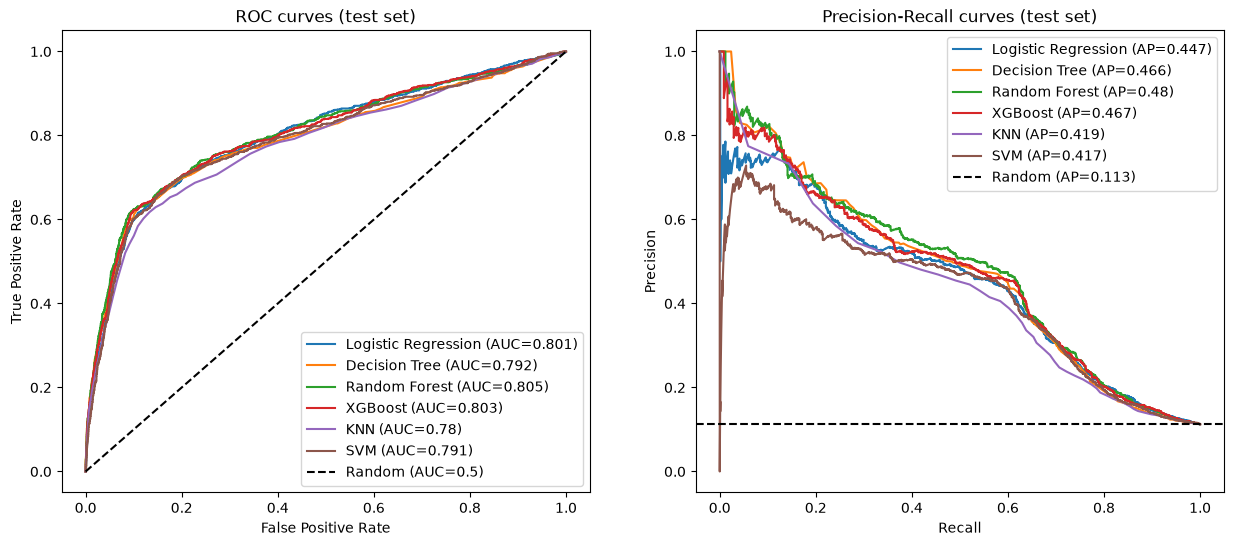

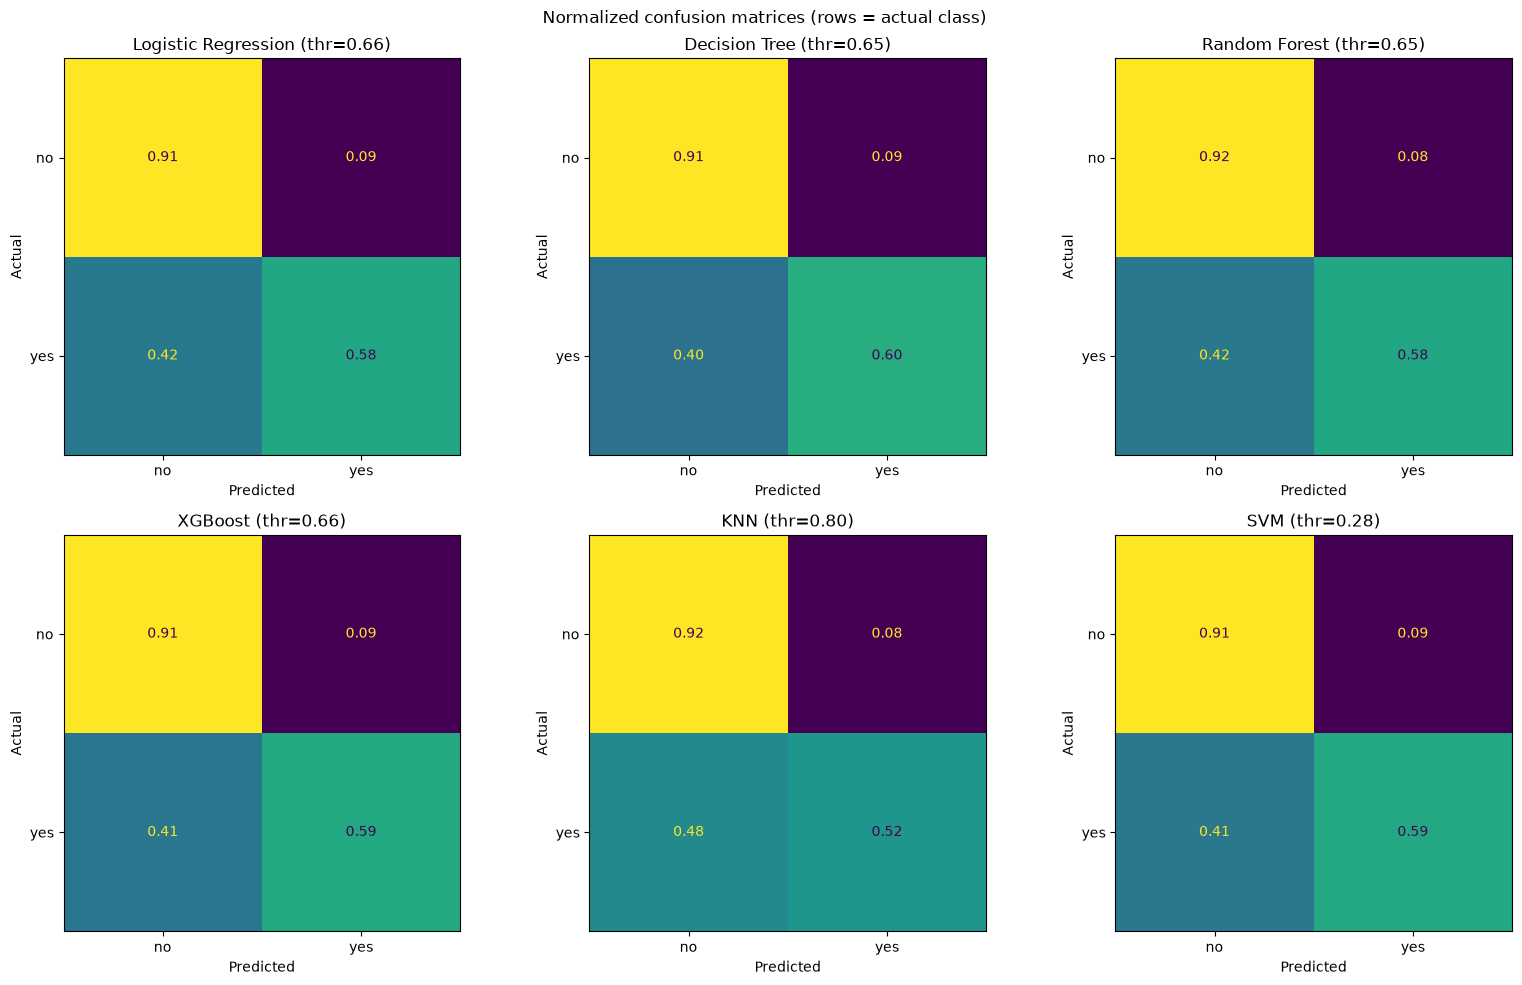

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for name in best_models:
    fpr, tpr, _ = roc_curve(y_test, y_proba[name])
    prec, rec, _ = precision_recall_curve(y_test, y_proba[name])
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={results.loc[name, 'ROC-AUC']})")
    ax[1].plot(rec, prec, label=f"{name} (AP={results.loc[name, 'PR-AUC']})")
ax[0].plot([0, 1], [0, 1], "k--", label="Random (AUC=0.5)")
ax[1].axhline(y_test.mean(), color="k", ls="--", label=f"Random (AP={y_test.mean():.3f})")
ax[0].set(title="ROC curves (test set)", xlabel="False Positive Rate", ylabel="True Positive Rate")
ax[1].set(title="Precision-Recall curves (test set)", xlabel="Recall", ylabel="Precision")
ax[0].legend(); ax[1].legend()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax_, name in zip(axes.ravel(), best_models):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred[name], ax=ax_, colorbar=False,
                                            display_labels=["no", "yes"], normalize="true",
                                            values_format=".2f")
    ax_.set(title=f"{name} (thr={best_thr[name]:.2f})", xlabel="Predicted", ylabel="Actual")
plt.suptitle("Normalized confusion matrices (rows = actual class)")
plt.tight_layout()
plt.show()

feature importance

Feature importance is shown for Random Forest, XGBoost and Logistic Regression because these models provide built-in importance measures (feature_importances_ and coefficients). KNN and kernel SVM have no native feature weights: KNN only stores the data and compares distances, and the RBF kernel works in an implicit feature space.

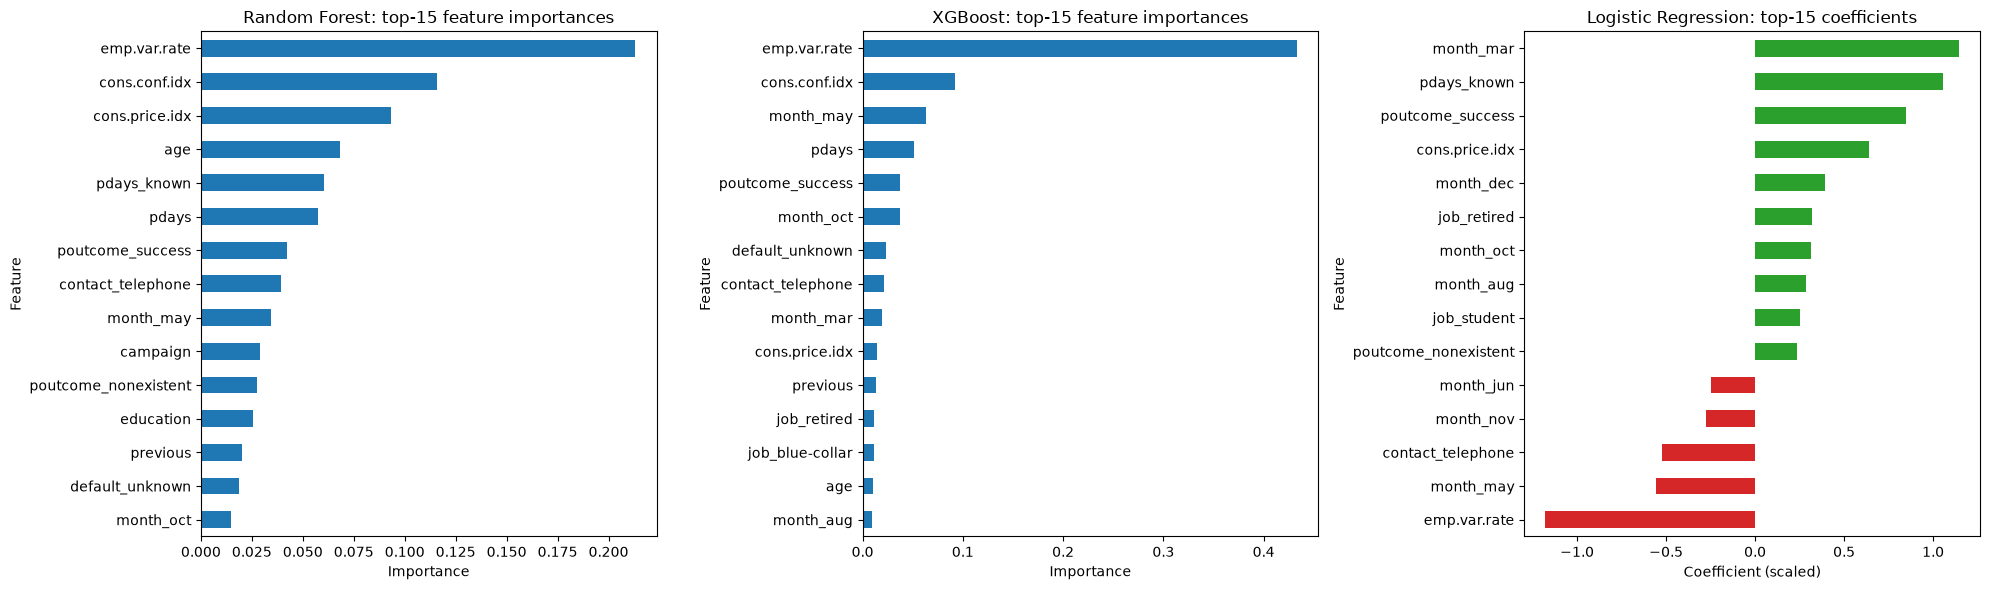

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, name in zip(axes[:2], ["Random Forest", "XGBoost"]):
    imp = pd.Series(best_models[name].feature_importances_,
                    index=X_train.columns).nlargest(15).sort_values()
    imp.plot(kind="barh", ax=ax)
    ax.set(title=f"{name}: top-15 feature importances", xlabel="Importance", ylabel="Feature")

coef = pd.Series(best_models["Logistic Regression"].coef_[0], index=X_train.columns)
coef = coef.reindex(coef.abs().nlargest(15).index).sort_values()
coef.plot(kind="barh", ax=axes[2], color=np.where(coef > 0, "tab:green", "tab:red"))
axes[2].set(title="Logistic Regression: top-15 coefficients", xlabel="Coefficient (scaled)",
            ylabel="Feature")
plt.tight_layout()
plt.show()

**Task:** Discuss the results. Summary of insights.

Random Forest is the best model: it has the highest PR-AUC, ROC-AUC and F1 and the highest precision for the “yes” class. XGBoost is almost as good. Tree-based ensembles perform best because they capture non-linear effects and interactions (e.g. age, month, economic period) and are robust to skewed features and outliers. Logistic Regression has a similar ROC-AUC but a lower PR-AUC, because a linear model cannot capture these non-linear patterns. KNN suffers from the high-dimensional one-hot feature space, and SVM was trained on only 8,000 rows for computational reasons.

All models are far better than random (PR-AUC 0.42–0.48 vs 0.116), but the differences between the best models are small (≈ 0.01–0.03). This suggests that performance is limited mainly by the available information. Without duration (excluded as leakage), predicting a client’s decision before the call is a genuinely hard task.

2. What the results mean in practice

With Random Forest at the tuned threshold, about 48% of the clients the model selects actually subscribe, more than 4 times the 11.3% success rate of random calling, and the model finds 58% of all subscribers. In the test set, the bank would make about 1,126 calls instead of 8,236 and still reach about 541 of the 928 subscribers. The threshold can be adjusted to the call-centre budget: a higher threshold gives fewer, more successful calls (higher precision), and a lower threshold reaches more subscribers (higher recall), as shown by the PR curve.

3. Summary of insights
The economy matters most. Macroeconomic indicators (emp.var.rate, related to Euribor and employment) are the strongest predictors: clients subscribed much more often in the low-interest, low-employment period of the 2009–2010 crisis, when they looked for safe savings.
Past behaviour predicts future behaviour. Clients who subscribed in a previous campaign agree again in ~65% of cases; previously contacted clients in general are more likely to subscribe.
The contact channel matters. Mobile phone calls convert about 3 times better than landline calls.
Timing matters. Targeted campaigns in March, September, October and December were far more successful than the mass-calling month of May.
More calls do not help. Most subscribers agreed within 1–3 calls; repeated calls to the same client rarely change the decision.
Client profile. Students and retired clients are the most likely subscribers, blue-collar workers the least; age has a non-linear effect.
Methodology. Under class imbalance, accuracy is misleading (our models have slightly lower accuracy than a model that always predicts “no”, but find 52–60% of subscribers). PR-AUC, F1 and threshold tuning are essential.
4. Recommendations for the bank
Use the Random Forest model to rank clients by subscription probability and call the top-ranked clients first.
Prioritise clients with a successful previous campaign and contact them via mobile phone.
Avoid mass untargeted campaigns and limit the number of calls per client to about 3.
Plan campaigns with the economic situation in mind: interest in term deposits rises when market interest rates are low.
5. Limitations and future work
duration was excluded to avoid data leakage; this lowers the metrics but makes the model usable before a call.
The macroeconomic features tie the model to the 2008–2010 period; it should be retrained on newer data before real use.
SVM was trained on a subsample, and the hyperparameter search was limited (randomized search with 8 combinations per model).
Possible improvements: a wider hyperparameter search, LightGBM/CatBoost, SMOTENC for mixed data, a cost-based threshold (cost of a call vs profit from a deposit) and an ensemble of the best models.